In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Fijar semilla global para reproducibilidad
SEED = 42
np.random.seed(SEED)
print("✅ Librerías cargadas y semilla fija en 42.")

✅ Librerías cargadas y semilla fija en 42.


In [2]:
#1.1 Cargar el archivo Excel (.xlsx) desde la ruta correcta
df = pd.read_excel("sample_data/Data_DG_Noice_pH_Ec_Hum_Patogen.xlsx")

#1.2 Visualizar las primeras 5 filas para verificar los datos
#print("🔍 Primeras 5 filas del dataset:")
#print(df.head())

#1.3 Verificar los nombres exactos de las columnas
#print("\n📋 Nombres de columnas detectadas:")
#print(df.columns.tolist())

#2. Diccionario para mapear los textos en indonesio a clases numéricas (0, 1, 2, 3)
mapeo_clases = {
    'Akar Sehat': 0,        # Sana
    'Busuk Akar Ringan': 1, # Leve
    'Busuk Akar Sedang': 2, # Moderada
    'Busuk Akar Berat': 3   # Severa
    }
# Crear la columna numérica 'Target'
df['Target'] = df['Kelas'].map(mapeo_clases)

#3. Separar las 9 características (X) de la variable objetivo (y)
X = df[['TGS832', 'TGS2620', 'TGS2600', 'TGS2603', 'TGS822', 'TGS826', 'pH', 'EC', 'Hum']]
y = df['Target']

print("✅ Dataset cargado correctamente.")
print(f"Dimensiones de X: {X.shape}")
print("\nConteo de muestras por clase numérica:")
print(y.value_counts().sort_index())

✅ Dataset cargado correctamente.
Dimensiones de X: (460, 9)

Conteo de muestras por clase numérica:
Target
0    100
1    120
2    120
3    120
Name: count, dtype: int64


In [3]:
# División 80% entrenamiento (368 muestras) y 20% prueba aislada (92 muestras)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
    )
print(f"Muestras de entrenamiento: {X_train.shape[0]}")
print(f"Muestras de prueba (aisladas): {X_test.shape[0]}")

Muestras de entrenamiento: 368
Muestras de prueba (aisladas): 92


In [4]:
scaler = StandardScaler()
# Fit solo en entrenamiento, transform en ambos
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convertir a DataFrames para mantener nombres de columnas
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X.columns)
print("✅ Preprocesamiento Z-Score aplicado correctamente sin data leakage.")

from sklearn.utils import resample
# Convertir temporalmente a DataFrame para re-muestrear la clase 0
df_train_temp = X_train_scaled.copy()
df_train_temp['Target'] = y_train.values

# Separar por clases
c0 = df_train_temp[df_train_temp['Target'] == 0] # 80 muestras
c1 = df_train_temp[df_train_temp['Target'] == 1] # 96 muestras
c2 = df_train_temp[df_train_temp['Target'] == 2] # 96 muestras
c3 = df_train_temp[df_train_temp['Target'] == 3] # 96 muestras

# Bootstrap con reemplazo para elevar la Clase 0 de 80 a 96 muestras
c0_resampled = resample(c0, replace=True, n_samples=96, random_state=SEED)

# Recombinar el dataset de entrenamiento balanceado (384 muestras)
df_train_balanced = pd.concat([c0_resampled, c1, c2, c3])

# Actualizar X\_train\_scaled e y\_train
X_train_scaled = df_train_balanced.drop(columns=['Target'])
y_train = df_train_balanced['Target']

print(f"✅ Bootstrap aplicado: {X_train_scaled.shape} muestras de entrenamiento (96 por clase).")

✅ Preprocesamiento Z-Score aplicado correctamente sin data leakage.
✅ Bootstrap aplicado: (384, 9) muestras de entrenamiento (96 por clase).


In [ ]:
# Definir el modelo base
#rf_base = RandomForestClassifier(n_estimators=100, random_state=SEED)

# SFS buscando el subconjunto óptimo (evaluando entre 3 y 8 variables)
#sfs_rf = SequentialFeatureSelector(
    #estimator=rf_base,
    #n_features_to_select='auto', # o fijar número como 5
    #direction='forward',
    #scoring='accuracy',
    #cv=5
    #)
#sfs_rf.fit(X_train_scaled, y_train)

# Obtener variables seleccionadas por SFS
#selected_features_rf = X.columns[sfs_rf.get_support()].tolist()
#print(f"🌲 Variables seleccionadas por SFS para Random Forest ({len(selected_features_rf)}):")
#print(selected_features_rf)

🌲 Variables seleccionadas por SFS para Random Forest (4):
['TGS832', 'TGS2620', 'pH', 'Hum']


In [6]:
import warnings
# Silenciar advertencias de convergencia en la pantalla de Colab
warnings.filterwarnings('ignore')

# 1. Definir los 4 clasificadores a evaluar
modelos = {
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=SEED),
    'SVM (RBF)': SVC(kernel='rbf', random_state=SEED),
    'MLP (Red Neuronal)': MLPClassifier(max_iter=1000, early_stopping=True, random_state=SEED),
    'XGBoost': XGBClassifier(random_state=SEED, eval_metric='mlogloss')
    }

modelos_entrenados = {}
features_por_modelo = {}

print("🔄 Ejecutando SFS de forma independiente para cada modelo...\n")

# 2. Bucle de SFS y entrenamiento individual
for nombre, modelo in modelos.items():
  sfs = SequentialFeatureSelector(
      estimator=modelo,
      n_features_to_select='auto',
      direction='forward',
      scoring='accuracy',
      cv=5
  )
  sfs.fit(X_train_scaled, y_train)

  # Extraer variables seleccionadas
  selected_cols = X.columns[sfs.get_support()].tolist()
  features_por_modelo[nombre] = selected_cols

  # Entrenar el modelo final con su subconjunto de variables
  X_tr_sfs = X_train_scaled[selected_cols]
  modelo.fit(X_tr_sfs, y_train)

  # Guardar en diccionario para la evaluación
  modelos_entrenados[nombre] = modelo

  print(f"✅ {nombre}: {len(selected_cols)} variables seleccionadas -> {selected_cols}")

print("\n🎉 ¡Entrenamiento y selección de características completados!")

🔄 Ejecutando SFS de forma independiente para cada modelo...

✅ Random Forest: 4 variables seleccionadas -> ['TGS832', 'TGS2620', 'pH', 'Hum']
✅ SVM (RBF): 4 variables seleccionadas -> ['TGS832', 'TGS822', 'pH', 'Hum']
✅ MLP (Red Neuronal): 4 variables seleccionadas -> ['TGS832', 'pH', 'EC', 'Hum']
✅ XGBoost: 4 variables seleccionadas -> ['TGS832', 'TGS2603', 'EC', 'Hum']

🎉 ¡Entrenamiento y selección de características completados!


📊 Reporte de Clasificación:
              precision    recall  f1-score   support

     Healthy       1.00      1.00      1.00        20
        Mild       1.00      1.00      1.00        24
    Moderate       1.00      1.00      1.00        24
      Severe       1.00      1.00      1.00        24

    accuracy                           1.00        92
   macro avg       1.00      1.00      1.00        92
weighted avg       1.00      1.00      1.00        92



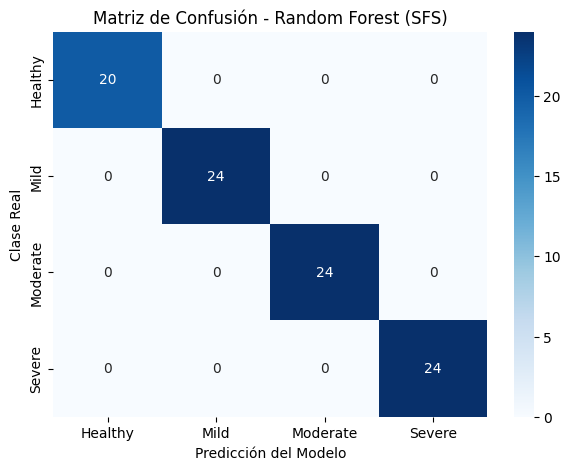

In [ ]:
# Filtrar características seleccionadas por SFS
#X_train_sfs = X_train_scaled[selected_features_rf]
#X_test_sfs = X_test_scaled[selected_features_rf]

# Entrenar modelo final
#rf_final = RandomForestClassifier(n_estimators=100, random_state=SEED)
#rf_final.fit(X_train_sfs, y_train)

# Predicción en el set de prueba aislado
#y_pred = rf_final.predict(X_test_sfs)

# Reporte de métricas
#print("📊 Reporte de Clasificación:")
#print(classification_report(y_test, y_pred, target_names=['Healthy', 'Mild', 'Moderate', 'Severe']))

# Graficar Matriz de Confusión
#plt.figure(figsize=(7, 5))
#cm = confusion_matrix(y_test, y_pred)
#sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            #xticklabels=['Healthy', 'Mild', 'Moderate', 'Severe'],
            #yticklabels=['Healthy', 'Mild', 'Moderate', 'Severe'])
#plt.title('Matriz de Confusión - Random Forest (SFS)')
#plt.xlabel('Predicción del Modelo')
#plt.ylabel('Clase Real')
#plt.show()

📊 TABLA COMPARATIVA DE DESEMPEÑO:


,Modelo,Cant. Var. SFS,Variables Seleccionadas,Accuracy,Precision,Recall,F1-Score
0,Random Forest,4,"TGS832, TGS2620, pH, Hum",100.0%,100.0%,100.0%,100.0%
1,SVM (RBF),4,"TGS832, TGS822, pH, Hum",100.0%,100.0%,100.0%,100.0%
2,MLP (Red Neuronal),4,"TGS832, pH, EC, Hum",93.5%,93.6%,93.8%,93.4%
3,XGBoost,4,"TGS832, TGS2603, EC, Hum",98.9%,99.0%,99.0%,99.0%


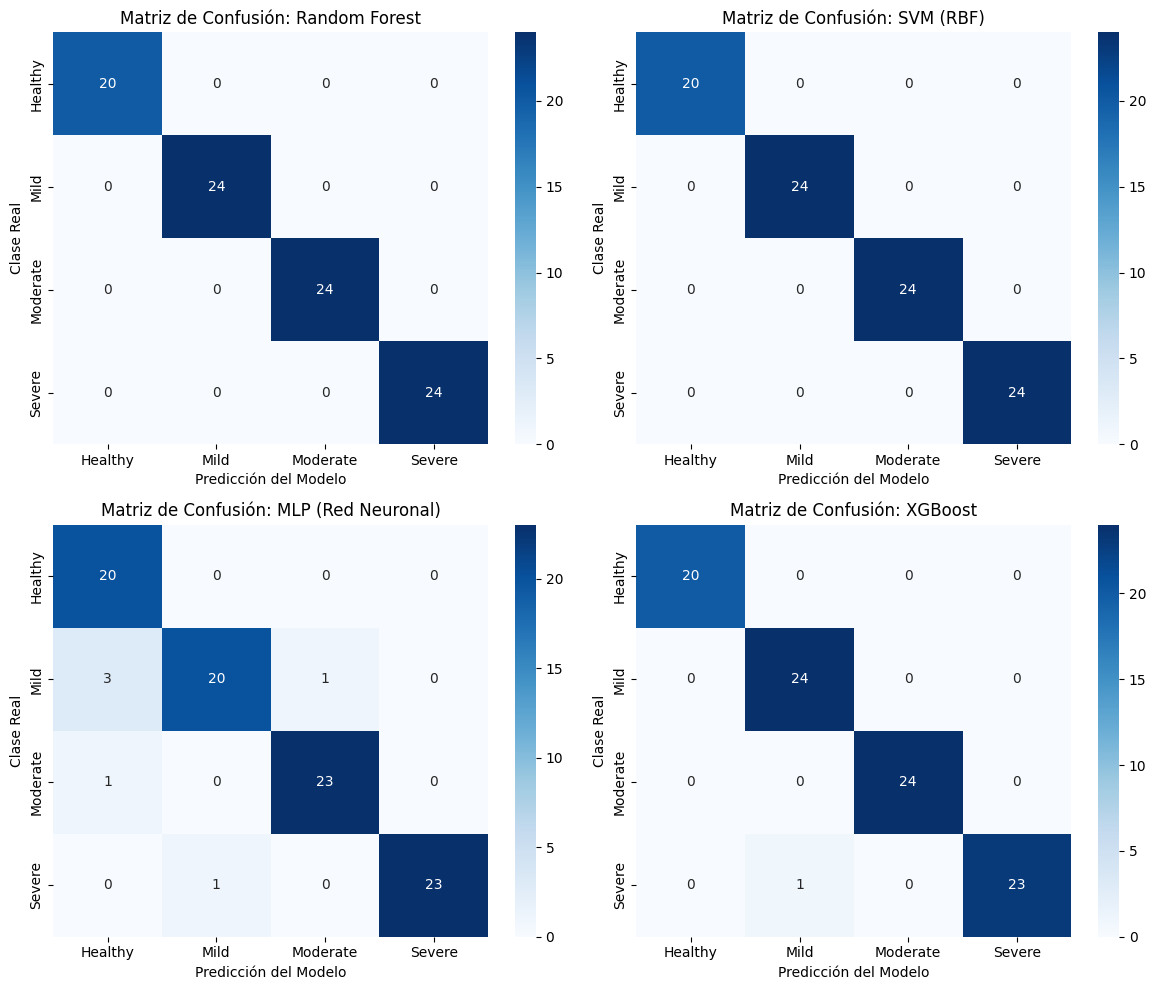

In [7]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
resultados = []
matrices_confusion = {}
clases = ['Healthy', 'Mild', 'Moderate', 'Severe']

# 1. Evaluar en el conjunto de prueba aislado (92 muestras)
for nombre, modelo in modelos_entrenados.items():
  selected_cols = features_por_modelo[nombre]
  X_te_sfs = X_test_scaled[selected_cols]

  y_pred = modelo.predict(X_te_sfs)

  acc = accuracy_score(y_test, y_pred)
  prec = precision_score(y_test, y_pred, average='macro')
  rec = recall_score(y_test, y_pred, average='macro')
  f1 = f1_score(y_test, y_pred, average='macro')

  resultados.append({
      'Modelo': nombre,
      'Cant. Var. SFS': len(selected_cols),
      'Variables Seleccionadas': ", ".join(selected_cols),
      'Accuracy': f"{acc*100:.1f}%",
      'Precision': f"{prec*100:.1f}%",
      'Recall': f"{rec*100:.1f}%",
      'F1-Score': f"{f1*100:.1f}%"
      })

  matrices_confusion[nombre] = confusion_matrix(y_test, y_pred)

# 2. Desplegar Tabla Resumen
df_resumen = pd.DataFrame(resultados)
print("📊 TABLA COMPARATIVA DE DESEMPEÑO:")
display(df_resumen)

# 3. Graficar Matriz de Confusión Cuádruple (2x2)
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i, (nombre, cm) in enumerate(matrices_confusion.items()):
  sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
              xticklabels=clases, yticklabels=clases)
  axes[i].set_title(f'Matriz de Confusión: {nombre}')
  axes[i].set_xlabel('Predicción del Modelo')
  axes[i].set_ylabel('Clase Real')

plt.tight_layout()
plt.show()